In [1]:

from collections import Counter
from collections import defaultdict

# Base
import math as m

# Base 2.0
import numpy as np
import pandas as pd

# Grafici
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# SciPy
from scipy import stats
from scipy.cluster.hierarchy import (
    dendrogram,
    fcluster,
    linkage,
)
from scipy.spatial.distance import pdist, squareform

# Scikit-learn
from sklearn.cluster import (
    AgglomerativeClustering,
    BisectingKMeans,
    cluster_optics_dbscan,
    DBSCAN,
    KMeans,
    OPTICS,
)
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    RidgeCV,
    Lasso,
    LassoCV,
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    roc_auc_score,
    r2_score,
    RocCurveDisplay,
    silhouette_score,
    silhouette_samples,
)
from sklearn.model_selection import (
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import (
    CategoricalNB,
    GaussianNB,
)
from sklearn.neighbors import (
    KNeighborsClassifier,
    NearestNeighbors,
    KNeighborsRegressor,
)
from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
)
from sklearn.tree import (
    DecisionTreeClassifier,
    DecisionTreeRegressor,
    plot_tree,
)
from pyod.models.knn import KNN
from scipy.spatial.distance import pdist, squareform
from tqdm import tqdm

# Librerie
import pandas as pd
import numpy as np

# High Dimensionality
from pyod.models.abod import ABOD

# Ensemble
from pyod.models.feature_bagging import FeatureBagging
# carico LOF per FeaBag, chiaramente si può cambiare a seconda del modello semplice scelto
from pyod.models.lof import LOF
from pyod.models.loda import LODA

# Foreste
from sklearn.ensemble import IsolationForest
from isotree import IsolationForest as EIF

from sklearn.manifold import TSNE


# REGRESSIONE
from lightgbm import LGBMRegressor
from sklearn.svm import SVR
from sklearn.ensemble import BaggingRegressor

In [40]:
# dataset
df = pd.read_parquet("df_pulito.parquet")
df["bmi"] = (df["Physical-Weight"] / (df["Physical-Height"] ** 2)) * 703

# veloce escamotage per elencare tutte le variabili questionario
'''pciat_cols = [f"PCIAT-PCIAT_{i:02d}" for i in range(1, 21)]
X = df.drop(columns=["sii","risultati", "PCIAT-PCIAT_Total", "id"] + pciat_cols)
y = df["sii"]'''  # per valutare sii, praticamente classificazione

'''X = df.drop(columns=['SDS-SDS_Total_Raw',
            "SDS-SDS_Total_T", "risultati", "id"])
y = df['SDS-SDS_Total_Raw']'''  # sleep disturbance

X = df.drop(columns=['Physical-Weight',
            "Physical-Height", "risultati", "bmi", "id"])
y = df['bmi']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=222)

In [41]:
# LightGBM
lgbm = LGBMRegressor(
    learning_rate=0.1,
    n_estimators=100,
    num_leaves=31,  # 31 perchè in un albero decisionale completo 5 Livelli = 2^5 = 32 foglie; limite di 31 viene usato per avere complessità paragonabile a livello 5
    random_state=222
)
lgbm.fit(X_train, y_train)

y_pred_lgbm = lgbm.predict(X_test)

print("LightGBM Model")
print("MAE:", mean_absolute_error(y_test, y_pred_lgbm))
print("MSE:", mean_squared_error(y_test, y_pred_lgbm))
print("R2:", r2_score(y_test, y_pred_lgbm))

feature_importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': lgbm.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("Top 5 feature per importanza:")
print(feature_importances.head(5))

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0,001345 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7516
[LightGBM] [Info] Number of data points in the train set: 5760, number of used features: 72
[LightGBM] [Info] Start training from score 17,579169
LightGBM Model
MAE: 2.4071130123336193
MSE: 17.231447876143083
R2: 0.38583284164679243
Top 5 feature per importanza:
                         Feature  Importance
6   Physical-Waist_Circumference         173
36                   BIA-BIA_Fat         128
35                   BIA-BIA_FMI         127
39                   BIA-BIA_LDM         126
38                   BIA-BIA_ICW         122


In [42]:
# SVR
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svr = SVR(kernel='rbf', C=1.0, epsilon=0.1)
svr.fit(X_train_scaled, y_train)

y_pred_svr_scaled = svr.predict(X_test_scaled)

print("SVR Model (Dati Standardizzati)")
print("MAE:", mean_absolute_error(y_test, y_pred_svr_scaled))
print("MSE:", mean_squared_error(y_test, y_pred_svr_scaled))
print("R2:", r2_score(y_test, y_pred_svr_scaled))

SVR Model (Dati Standardizzati)
MAE: 2.650927945271279
MSE: 19.891109070688064
R2: 0.2910365964457414


In [43]:
# BaggingRegressor
bagging = BaggingRegressor(
    n_estimators=100,
    max_samples=0.7,
    max_features=1.0,
    random_state=222
)
bagging.fit(X_train, y_train)

y_pred_bagging = bagging.predict(X_test)

print("BaggingRegressor Model")
print("MAE:", mean_absolute_error(y_test, y_pred_bagging))
print("MSE:", mean_squared_error(y_test, y_pred_bagging))
print("R2:", r2_score(y_test, y_pred_bagging))

BaggingRegressor Model
MAE: 2.3357273204919724
MSE: 16.950984835495802
R2: 0.3958291687073827


In [ ]:
# CONCLUSIONI
# se si rimuovono le variabili del questionario, allora i modelli fanno cahare; se si tengono le variabili questionario i modelli hanno R2 > 95%

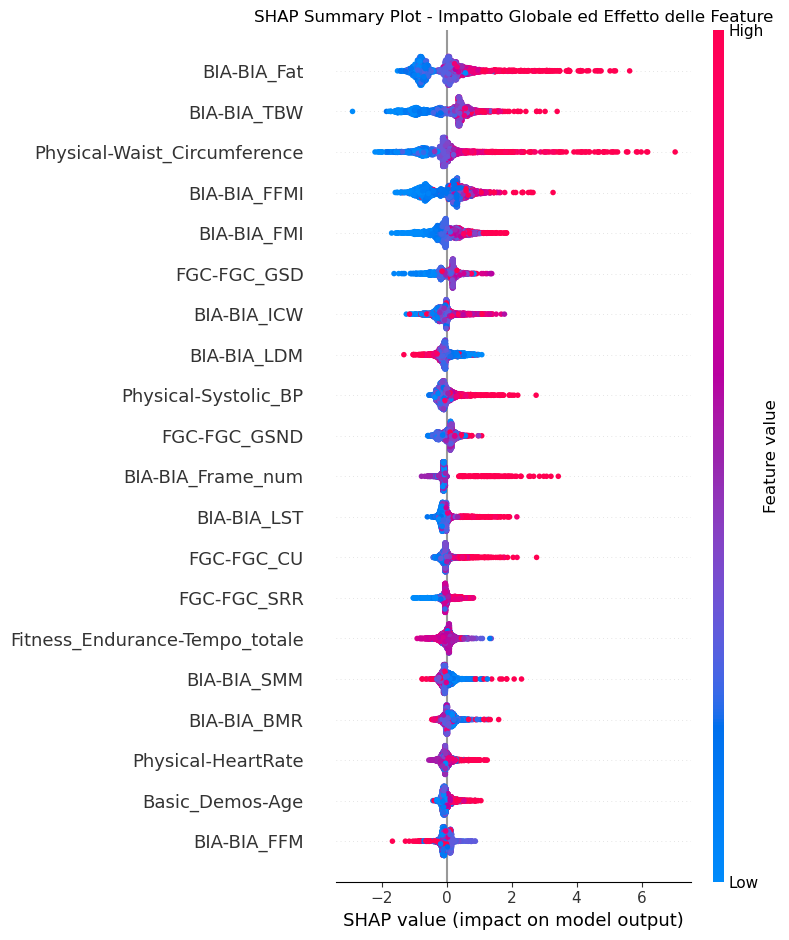

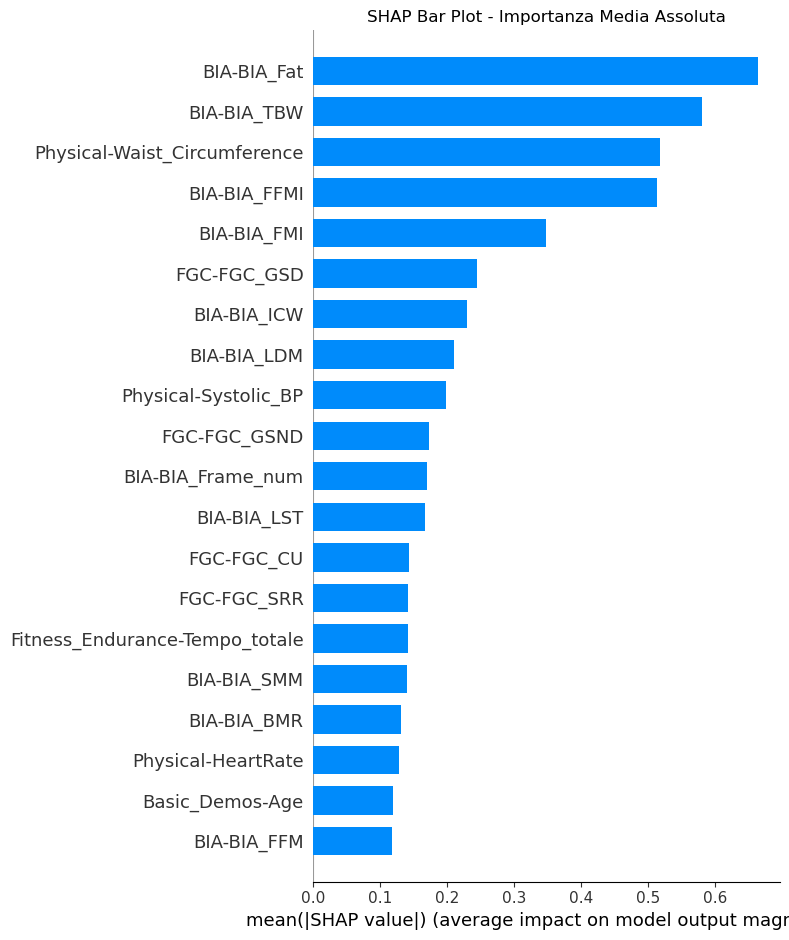

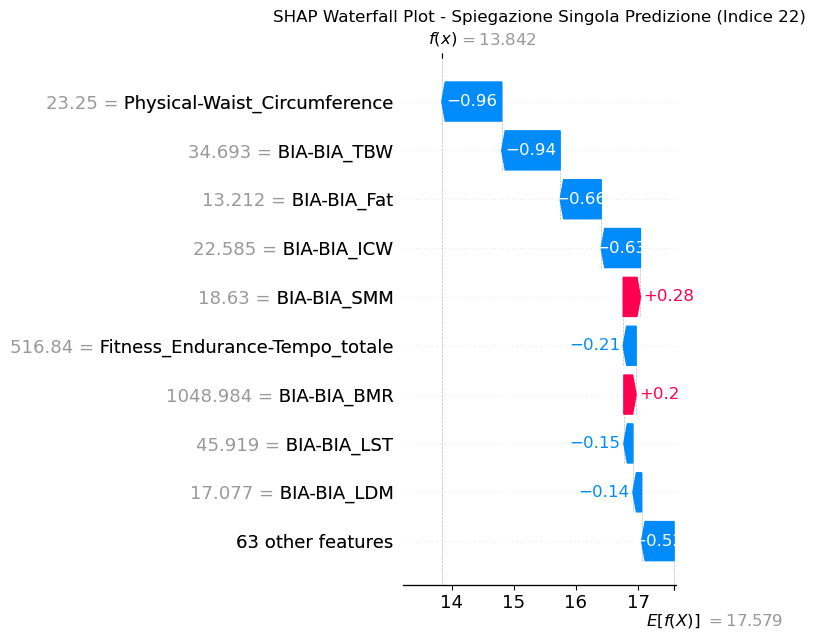

In [44]:
# SHAP su LGBM
import shap
import matplotlib.pyplot as plt

# 1. Inizializzazione dell'Explainer
# TreeExplainer è progettato specificamente per ottimizzare il calcolo SHAP su modelli ad albero
explainer = shap.TreeExplainer(lgbm)

# 2. Calcolo dei valori SHAP
# Si utilizza il test set per valutare l'impatto delle variabili su dati non visti durante l'addestramento
shap_values = explainer.shap_values(X_test)

# ==========================================
# SPIEGAZIONE GLOBALE (Global Explainability)
# ==========================================

# Summary Plot (Dot): Mostra la distribuzione dell'impatto di ciascuna variabile.
# I colori indicano il valore reale della feature (alto/basso), la posizione sull'asse X indica
# l'impatto sulla predizione (sii).
plt.figure()
shap.summary_plot(shap_values, X_test, plot_type="dot", show=False)
plt.title("SHAP Summary Plot - Impatto Globale ed Effetto delle Feature")
plt.tight_layout()
plt.show()

# Summary Plot (Bar): Fornisce una classifica classica dell'importanza delle variabili
# basata sulla media del valore assoluto dei valori SHAP.
plt.figure()
shap.summary_plot(shap_values, X_test, plot_type="bar", show=False)
plt.title("SHAP Bar Plot - Importanza Media Assoluta")
plt.tight_layout()
plt.show()

# ==========================================
# SPIEGAZIONE LOCALE (Local Explainability)
# ==========================================

# Selezione di una singola osservazione dal set di test per spiegarne la predizione specifica
osservazione_idx = 22
dati_osservazione = X_test.iloc[osservazione_idx]

# Creazione dell'oggetto Explanation richiesto dalla nuova API di SHAP per grafici avanzati
shap_exp = shap.Explanation(
    values=shap_values[osservazione_idx],
    base_values=explainer.expected_value,
    data=dati_osservazione.values,
    feature_names=X_test.columns
)

# Waterfall Plot: Illustra il percorso decisionale partendo dal valore base (media di tutte le predizioni)
# fino al valore effettivamente predetto per questa singola istanza, quantificando il contributo
# positivo o negativo di ogni singola variabile.
plt.figure()
shap.plots.waterfall(shap_exp, max_display=10, show=False)
plt.title(
    f"SHAP Waterfall Plot - Spiegazione Singola Predizione (Indice {osservazione_idx})")
plt.tight_layout()
plt.show()